# Clasificación de textos con Transformer y Hugging Face

Creado por: Luis Norberto Zúñiga Morales para el módulo 4 del diplomado *Big Data & Data Analytics*.

Universidad Iberoamericana Ciudad de México. Verano 2025.

Objetivos:

- Introducir al estudiante al flujo de trabajo de Hugging Face para el proceso de clasificación de un conjunto de datos.
- Explorar conceptos como tokenizadores, modelos y entrenamiento de modelos.
- Analizar errores y rendimientos de los modelos usando una matriz de confusión.



---



En esta ocasión vamos a construir un modelo para realizar análisis de emociones sobre publicaciones en redes sociales con una variante de BERT llamada DistilBERT, la cual es más pequeña y eficiente, logrando casi el mismo rendimiento que su hermano mayor.

Además, esto nos servirá para introducir tres librerías clave del ecosistemas de Hugging Face: `Datasets`, `Tokenizers`, `Transformers`.

¡¡RECUERDEN CAMBIAR EL ENTORNO DE EJECUCIÓN A GPU!!

## Instalación de librerías

In [1]:
!pip install datasets

In [2]:
!pip install transformers

In [3]:
!pip install accelerate

In [4]:
!pip install tensorflow --upgrade

## El conjunto de datos

Vamos a utilizar el conjunto de datos empelado en la investigación de Saravia et al.$^1$, el cual consta de tuits en inglés etiquetados en 6 emociones distintas: ira (*anger*), disgusto (*disgust*), miedo (*fear*), felicidad (*joy*), tristeza (*sadness*) y sorpresa (*surprise*). Dado un tuit, queremos determinar cuál de las emociones se encuentra presente.

$^1$ https://aclanthology.org/D18-1404/

Vamos a utilizar la librería `Datasets` para descargar los datos del Hub de Hugging Face:

In [5]:
from datasets import load_dataset

In [7]:
emotions = load_dataset('dair-ai/emotion')

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [10]:
emotions

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Al ver el objeto `emotions` , pordemos ver que se parece a un Diccionario de Python,, donde cada llave corresponde a una partición diferente. Para el entrenamiento de un modelo de ML o DL, es necesario separar los datos en tres subconjuntos: uno de entrenamiento (para entrenar el modelo), uno de prueba (para evaluar el rendimiento del modelo al final) y uno de validación (para realizar evaluaciones con hiperpárametros y entre entrenamientos).

Noten que es posible acceder a los elementos del Dataset usando sintaxis usual para acceder a los elementos de un diccionario:

In [11]:
train_ds = emotions['train']

In [12]:
train_ds

Dataset({
    features: ['text', 'label'],
    num_rows: 16000
})

Además, se comporta como una lista o arreglo de Python, por lo que podemos determinar su longitud:

In [13]:
len(train_ds)

16000

o acceder puntualmente a un elemento usando la sintaxis de índice:

In [14]:
train_ds[1]

{'text': 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake',
 'label': 0}

donde podemos ver que cada elemento se representa como un diccionario, donde las llaves son los nombres de las columnas:

In [15]:
train_ds.column_names

['text', 'label']

y los valores son el tuit y la etiqueta de la emoción que le corresponde, respectivamente. Si queremos saber qué tipo de datos se usan en cada columna:

In [16]:
print(train_ds.features)

{'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


A pesar de ser convenientes, es mejor limitar el uso de una instancia de `Datasets` para cargar datos, y para manejarlos migrar a un `DataFrame` de Pandas. Esto nos da acceso a múltiples características y funciones que nos pueden ayudar a analizar los datos. `Datasets` nos provee de un método llamado `set_format` que nos permite cambiar el formato de salida del `Dataset`.

In [17]:
import pandas as pd

In [18]:
emotions.set_format(type='pandas')
df = emotions['train'][:]
df.head()

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


Noten que lo último que cambió fue que las etiquetas tiene ahora una representación numérica, por lo que vamos a utilizar el método `int2str()` de `label` para crear una nueva columna en el `DataFrame` que contenga la etiqueta original:

In [19]:
def label_int2str(row):
  return emotions['train'].features['label'].int2str(row)

In [20]:
df['label_name'] = df['label'].apply(label_int2str)
df.head()

,text,label,label_name
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger


## Un poco de exploración de los datos

Comenzamos analizando la distribución de cada clase o emoción en nuestros datos (recuerden que es el conjunto de entrenamiento únicamente):

In [21]:
import matplotlib.pyplot as plt

In [22]:
df['label_name'].value_counts(ascending=True)

,count
label_name,
surprise,572
love,1304
fear,1937
anger,2159
sadness,4666
joy,5362


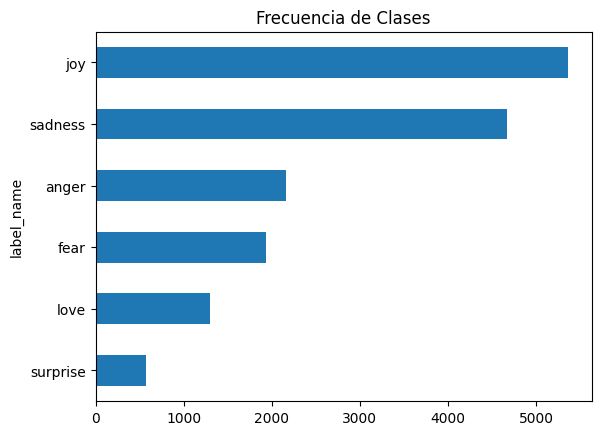

In [23]:
df['label_name'].value_counts(ascending=True).plot.barh()
plt.title('Frecuencia de Clases')
plt.show()

¿Qué alcanzan a apreciar en la gráfica?

Los modelos basados en Transformer tienen un límite máximo para la longitud de la secuencia que se alimenta al modelo. Para DistilBERT, esta longitud es de 512 tokens. Un token es la parte medular de como alimentamos a los modelos, y se puede entender como las palabras de un texto o documento.

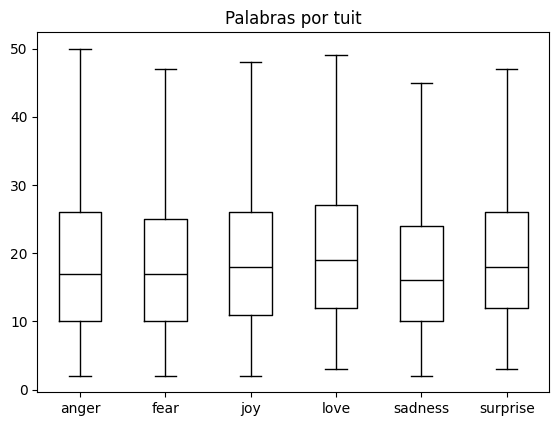

In [24]:
df['Palabras por tuit'] = df['text'].str.split().apply(len)
df.boxplot('Palabras por tuit', by='label_name', grid=False, showfliers =False, color = 'black')
plt.suptitle('')
plt.xlabel('')
plt.show()

¿Cómo interpretan esta gráfica de cajas?

Lo anterior nos dice lo siguiente:

1. Trabajamos con un conjunto de datos desequilibrado, lo cual complica el entrenamiento de modelos.
2. Los tuits no son muy largos, lo cual se ajusta bien al modelo de DistilBERT.

## Tokens

Los modelos basados en Transformer no pueden recibir las cadenas de texto *crudas*. En su lugar, debemos someterlas a dos procesos: la *tokenización* y una *codificación* a un vector numérico.

- Tokenización: se parte una cadena de texto en sus unidades más elementales, que muchas veces coincide con las palabras que la forman. Existen diversos esquemas, y varían de idioma a idioma. Cada modelo (como DistilBERT) suele manejar el propio.


Por ejemplo, una forma de tokenizar es a nivel letra:

In [25]:
text = 'No me gusta ir a la escuela.'
tokenized_text = list(text)
print(tokenized_text)

['N', 'o', ' ', 'm', 'e', ' ', 'g', 'u', 's', 't', 'a', ' ', 'i', 'r', ' ', 'a', ' ', 'l', 'a', ' ', 'e', 's', 'c', 'u', 'e', 'l', 'a', '.']


Lo anterior nos permite separar la oración en esta unidad atómica, pero falta convertirlo a una representación numérica. Lo más sencillo es asignar a cada token (o caracter, en este caso), con un entero único:



In [26]:
token2id = {char: id for id, char in enumerate(sorted(set(tokenized_text)))}
print(token2id)

{' ': 0, '.': 1, 'N': 2, 'a': 3, 'c': 4, 'e': 5, 'g': 6, 'i': 7, 'l': 8, 'm': 9, 'o': 10, 'r': 11, 's': 12, 't': 13, 'u': 14}


Es decir, obtenemos un mapa de cada caracter de nuestro vocabulario a un número entero (una relación, pues). Ya con este mapa, podemos convertir cualquier cadena de texto a su representación numérica:

In [27]:
input_ids = [token2id[token] for token in tokenized_text]
print(input_ids)

[2, 10, 0, 9, 5, 0, 6, 14, 12, 13, 3, 0, 7, 11, 0, 3, 0, 8, 3, 0, 5, 12, 4, 14, 5, 8, 3, 1]


Otra forma puede ser, en lugar de a nivel caracter, a nivel palabra:

In [28]:
tokenized_text = text.split()
print(tokenized_text)

['No', 'me', 'gusta', 'ir', 'a', 'la', 'escuela.']


En este caso, realizar la tokenización a nivel palabra es un poco más complejo:

- Dependemos del total de todas las palabras únicas (el vocabulario) de nuestro conjunto de datos.
- Entre más datos, mayor es el tamaño del vocabulario, lo cual resulta en una cantidad mayor de parámetros que debe aprender nuestra red neuronal.
 - Por ejemplo, si tenemos un vocabulario de 100,000 palabras, el tamaño del vector es de tamaño 100,000, lo cual sería una capa de entrada de 100,000 neuronas.

Para aliviar este problema, se propuso un esquema de tokenización llamado *Subword Tokenization*, que mezcla ideas de los esquemas basados en palabras y caracteres, y es la que utilizan BERT y DistilBERT. Vamos a verla en acción.

In [29]:
from transformers import AutoTokenizer

In [30]:
model_ckpt = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Hugging Face tiene métodos `Auto` cuyo trabajo es buscar y encontrar configuraciones, parámetros o vocabularios de los modelos que estemos utilizando, dado el nombre del modelo (en la variable `model_ckpt`). Esto nos permite cambiar de un modelo a otro de forma sencilla. Para hacerlo manualmente, en este caso:

In [31]:
print(tokenizer)

BertTokenizer(name_or_path='distilbert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})


In [32]:
from transformers import DistilBertTokenizer

In [33]:
distilbert_tokenizer = DistilBertTokenizer.from_pretrained(model_ckpt)

In [34]:
text = 'Let\'s tokenize this piece of text!'
encoded_text = tokenizer(text)
print(encoded_text)

{'input_ids': [101, 2292, 1005, 1055, 19204, 4697, 2023, 3538, 1997, 3793, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [35]:
tokens = tokenizer.convert_ids_to_tokens(encoded_text.input_ids)
print(tokens)

['[CLS]', 'let', "'", 's', 'token', '##ize', 'this', 'piece', 'of', 'text', '!', '[SEP]']


## Tokenizando nuestros datos

Ya que entendemos como tokenizar y codificar nuestro texto, necesitamos aplicarlo a cada tuit de nuestro conjunto de datos. Para facilitar las cosas, vamos a utilizar el método `map()` de nuestro objeto `DatasetDict`. La idea es que nos permite aplicar una función a cada elemento del conjunto de datos. Primero vamos a definir la función de tokenización a mapear:

In [45]:
def tokenize(batch):
  return tokenizer(batch['text'], padding=True, truncation=True)

La función anterior aplica la tokenización a un conjunto de tuits. `padding=True` rellena de ceros la secuencia final para que todos los vectores tengan la misma longitud. Finalmente, `truncation=True` trunca los tuits que tengan una longitud máxima de 512 hasta el caracter 512, cuidando que todas tengan la misma longitud máxima.

In [46]:
emotions.set_format(type=None) # Antes cambiamos el formato a Pandas, debemos reiniciarlo, si no sale error

In [47]:
print(emotions['train'][:2])

{'text': ['i didnt feel humiliated', 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake'], 'label': [0, 0]}


In [48]:
tokenize(emotions['train'][:2])

{'input_ids': [[101, 1045, 2134, 2102, 2514, 26608, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [101, 1045, 2064, 2175, 2013, 3110, 2061, 20625, 2000, 2061, 9636, 17772, 2074, 2013, 2108, 2105, 2619, 2040, 14977, 1998, 2003, 8300, 102]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]}

Creamos nuestro conjunto de datos ya procesados y listos para alimentarlos al modelo de clasificación:

In [49]:
emotions_encoded = emotions.map(tokenize, batched=True, batch_size=None)

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

## Entrenamiento de un clasificador

Los modelos grandes de lenguaje se encuentran entreandos con tareas diversas que rara vez se ajustan a lo que necesitamos. Por ejemplo, una de las tareas con las que se entrenó BERT es, dada una secuencia de palabras, predecir la siguiente palabra, que se encuentra enmascarada. Esto no tiene nada que ver con clasificación, pero se puede adaptar agregando una cabeza de clasificación.

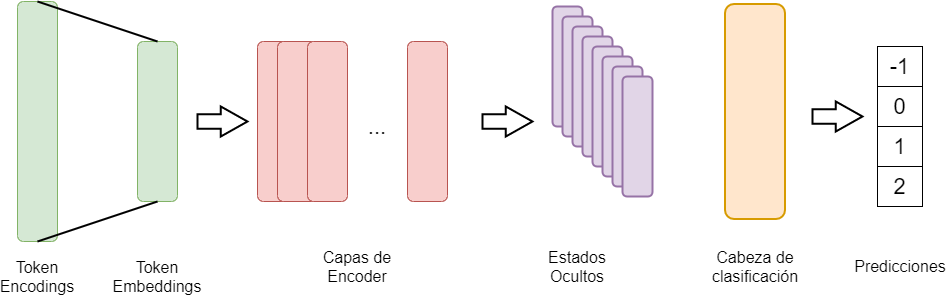

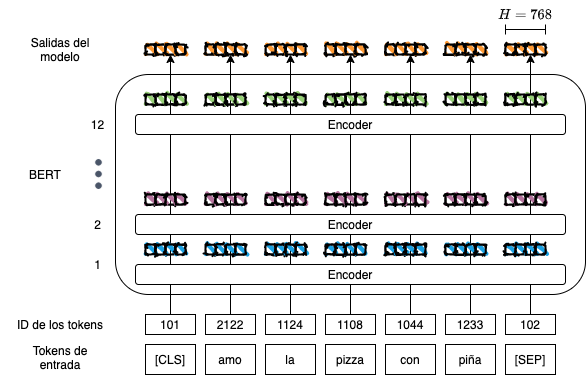

Con este en mente, existen dos caminos a seguir:

- Extracción de características: es una técnica usual para alimentar de vectores a distintos modelos de clasificación (redes neuronales, árboles de decisión, máquinas de vectores de soporte, etc.). No se modifica el modelo, solo se presenta el texto y lo transforma en un vector.

- Fine-tuning: se entrena todo el modelo, de inicio a fin y viceversa, lo que modifica los parámetros del mismo.

En esta ocasión, solo vamos a considerar Fine-tuning con nuestros datos.

### Fine-tuning

La idea de aplicar fine-tuning a un modelo es ajustarlo con nuestros datos. De esta manera, no iniciamos desde cero y el modelo se entrena para minimizar el error generado en las predicciones.

In [36]:
import torch

In [37]:
from transformers import AutoModelForSequenceClassification

In [38]:
num_labels = 6
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # 'mps'
model = (AutoModelForSequenceClassification.from_pretrained(model_ckpt, num_labels = num_labels, ignore_mismatched_sizes=True).to(device))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [39]:
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, matthews_corrcoef, confusion_matrix
import numpy as np
import itertools

In [40]:
def compute_metrics(pred):
	labels = pred.label_ids
	preds = pred.predicitions.argmax(-1)
	f1 = f1_score(labels, preds, average = 'weighted')
	acc = accuracy_score(labels, preds)
	return {'accuracy': acc, 'f1': f1}

In [41]:
def compute_metrics(p):
	pred, labels = p
	pred = np.argmax(pred, axis=1)
	accuracy = accuracy_score(y_true=labels, y_pred=pred)
	balanced_accuracy = balanced_accuracy_score(y_true=labels, y_pred=pred)
	matthews_corr = matthews_corrcoef(y_true=labels, y_pred=pred)
	f1 = f1_score(y_true=labels, y_pred=pred, average = 'weighted')
	return {"accuracy": accuracy, "balanced_accuracy": balanced_accuracy, "matthews_corr": matthews_corr, "f1": f1}

Ya que definimos las métricas, solo nos falta definir los hiperparámetros para realizar el entrenamiento de nuestra red.

In [42]:
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback

In [43]:
batch_size = 64
# logging_steps = len(emotions_encoded) // batch_size
model_name = f'{model_ckpt}-finetuned-emotions'
training_args = TrainingArguments(output_dir = model_name,
                                num_train_epochs = 2,
                                learning_rate = 2e-5,
                                # label = ['overall_sent'],
                                report_to= 'none',
                                per_device_train_batch_size = batch_size,
                                per_device_eval_batch_size = batch_size,
                                weight_decay = 0.01,
                                eval_strategy = 'epoch',
                                save_strategy = 'epoch',
                                push_to_hub = False,
                                metric_for_best_model = 'f1',
                                load_best_model_at_end = True,
                                disable_tqdm = False,
                                # logging_steps = logging_steps,
                                log_level = 'error')

Con esto podemos iniciar el entrenamiento del modelo:

In [50]:
trainer = Trainer(model = model,
                  args = training_args,
                  compute_metrics = compute_metrics,
                  train_dataset = emotions_encoded['train'],
                  eval_dataset = emotions_encoded['validation'],
                  callbacks = [EarlyStoppingCallback(early_stopping_patience=1)]
                  )

In [51]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Balanced Accuracy,Matthews Corr,F1
1,No log,0.310080,0.914500,0.875596,0.887311,0.914066
2,0.538771,0.211880,0.930000,0.897455,0.908120,0.929875


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=500, training_loss=0.5387705078125, metrics={'train_runtime': 260.98, 'train_samples_per_second': 122.615, 'train_steps_per_second': 1.916, 'total_flos': 720342861696000.0, 'train_loss': 0.5387705078125, 'epoch': 2.0})

Ahora, vamos a visualizar con mayor detalle nuestras métricas de **entrenamiento** calculando la matriz de confusión. Para calcularla, necesitamos obtener las predicciones en el conjunto de validación (que se suministró durante esa fase):

In [52]:
preds = trainer.predict(emotions_encoded['validation'])

In [53]:
y_pred = np.argmax(preds.predictions, axis=1) # [0, 0.1, 0.1, 0.8, 0, 0] --> 3  # valores que predice el modelo

In [54]:
y_valid = np.array(emotions['validation']['label']) # valores correctos

In [55]:
labels = emotions['train'].features['label'].names

In [56]:
def plot_confusion_matrix(cm, classes, normalize=False, title='Normalized Confusion Matrix', cmap=plt.cm.Blues):
	"""
	This function prints and plots the confusion matrix.
	Normalization can be applied by setting `normalize=True`.
	"""
	if normalize:
		cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
		print("Normalized confusion matrix")
	else:
		print('Confusion matrix, without normalization')

	print(cm)

	plt.imshow(cm, interpolation='nearest', cmap=cmap, aspect='auto')
	plt.title(title)
	plt.colorbar()
	tick_marks = np.arange(len(classes))
	plt.xticks(tick_marks, classes, rotation=45)
	plt.yticks(tick_marks, classes)

	fmt = '.2f' if normalize else 'd'
	thresh = cm.max() / 2.
	for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
		plt.text(j, i, format(cm[i, j], fmt),horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

	#plt.tight_layout()
	plt.ylabel('True label')
	plt.xlabel('Predicted label')

Normalized confusion matrix
[[0.96363636 0.00545455 0.00181818 0.01090909 0.01818182 0.        ]
 [0.00994318 0.94034091 0.03409091 0.00568182 0.00852273 0.00142045]
 [0.02247191 0.08426966 0.89325843 0.         0.         0.        ]
 [0.03272727 0.00727273 0.         0.93818182 0.02181818 0.        ]
 [0.03301887 0.01415094 0.         0.03773585 0.89622642 0.01886792]
 [0.01234568 0.08641975 0.01234568 0.         0.13580247 0.75308642]]


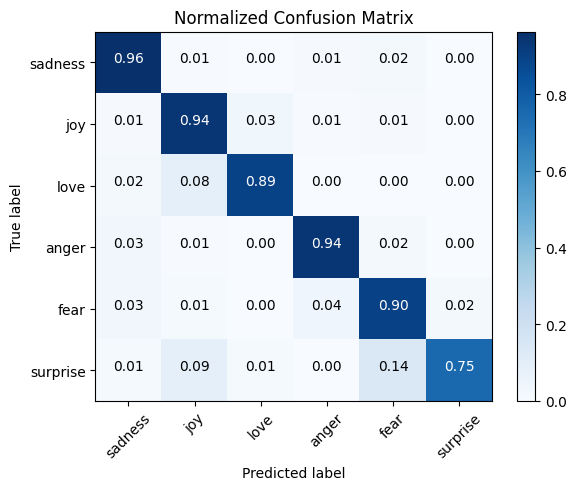

In [57]:
plot_confusion_matrix(confusion_matrix(y_valid, y_pred), labels, normalize=True)

Vamos a hacer lo mismo, pero con el conjunto de prueba, para visualizar la diferencia:

In [58]:
preds = trainer.predict(emotions_encoded['test'])

In [59]:
y_pred = np.argmax(preds.predictions, axis=1)

In [60]:
y_valid = np.array(emotions['test']['label'])

Normalized confusion matrix
[[0.95697074 0.0172117  0.         0.01549053 0.01032702 0.        ]
 [0.0057554  0.9352518  0.05467626 0.00431655 0.         0.        ]
 [0.00628931 0.16981132 0.81132075 0.01257862 0.         0.        ]
 [0.05090909 0.01454545 0.         0.92727273 0.00727273 0.        ]
 [0.03571429 0.         0.         0.03125    0.89285714 0.04017857]
 [0.04545455 0.12121212 0.01515152 0.         0.21212121 0.60606061]]


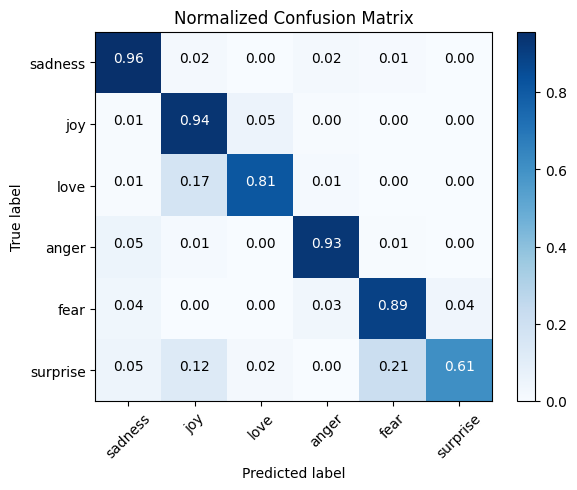

In [61]:
plot_confusion_matrix(confusion_matrix(y_valid, y_pred), labels, normalize=True)

Algunos detalles:

- En sí, usamos muy pocas `epochs` para entrenar el modelo, por lo que no sabemos si puede mejorar y cuanto. Para evitar entrenamiento de más, usamos una técnica llamada `EarlyStopping`, que evalúa el rendiemiento de cada epoch y, si no mejora o no supera cierto valor de tolerancia ciertas veces (la paciencia), se para el entrenamiento y se asumen que se llegó al mejor modelo.
- Tenemos muchos datos para entrenar neustro modelo, y se refleja en los resultados de evaluación.
- A pesar del desbalance de las clases, estamos obteniendo buenos resultados.

## Unas últimas predicciones

Vamos a terminar esta práctica construyendo un `pipeline` con nuestro modelo recién entrenado. Para esto, solo tenemos que pasar como argumento el directorio con los archivos necesarios.

In [62]:
from transformers import pipeline, DistilBertTokenizer, DistilBertForSequenceClassification

Aquí declaramos nuestro modelo propio, dónde se encuentra, y el tokenizador, que es el mismo que el que maneja Distilbert.

In [63]:
new_model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased-finetuned-emotions/checkpoint-500")
tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Creamos nuestro `pipeline` con la tarea de clasificación de texto con los argumentos que definimos anteriormente: `new_model` y `tokenizer`.

In [64]:
clf = pipeline("text-classification", model = new_model, tokenizer=tokenizer)

Creamos un tuit personal para probar el modelo entrenado con el dataset:

In [65]:
my_tweet = 'I went to the opera yesterday and it was not my thing.'

In [69]:
preds = clf(my_tweet, top_k = None) #deprecate return_all_scores

In [70]:
preds

[{'label': 'LABEL_0', 'score': 0.6014847755432129},
 {'label': 'LABEL_3', 'score': 0.1905931830406189},
 {'label': 'LABEL_1', 'score': 0.103369802236557},
 {'label': 'LABEL_4', 'score': 0.07094083726406097},
 {'label': 'LABEL_2', 'score': 0.02072739414870739},
 {'label': 'LABEL_5', 'score': 0.012883991003036499}]

Finalmente visualizamos las probabilidades de que pertenezca a cada clase (emoción). Lo más práctico es agarrar la que tenga mayor valor (`argmax`), pero es útil visualizar este tipo de resultados por si el modelo arroja una decisión donde dos o más clases tengan valores muy cercanos.

In [71]:
sust_dict = {'LABEL_0': 'sadness',
 'LABEL_1': 'joy',
 'LABEL_2': 'love',
 'LABEL_3': 'anger',
 'LABEL_4': 'fear',
 'LABEL_5': 'surprise'}

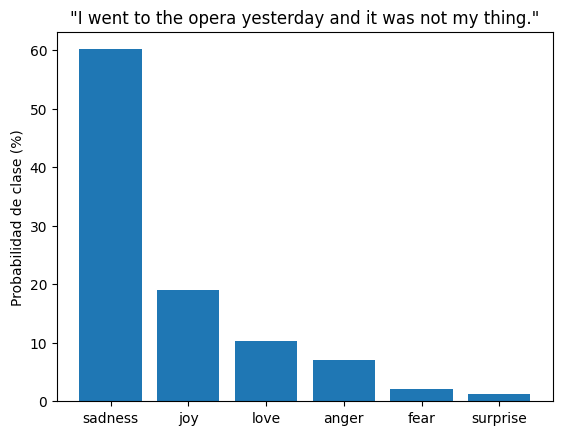

In [72]:
preds_df = pd.DataFrame(preds) #ahora regresa lista de diccionarios
plt.bar(labels, 100*preds_df['score'], color = 'C0')
plt.title(f'"{my_tweet}"')
plt.ylabel('Probabilidad de clase (%)')
plt.show()

En el caso anterior, el modelo infiere que el tuit refleja tristeza. ¿Están deacuerdo con el resultado?

## Tarea

1. [4 Puntos] Buscar en qué consisten los siguientes conceptos de métricas de evaluación de modelos de clasficación (escribir un pequeño resumen):

 - Matriz de confusión (*confusion matrix*)
 - Medida F1 (*F1-score*)
 - Coeficiente de correlación de Matthews (*Matthews Correlation Coefficient*)
 - Exactitud (*Accuracy*)


2. [6 Puntos] Busquen tres tuits en inglés y usen el texto para realizar algunas prediciones con el modelo ya entrenado. Muestren sus gráficas respectivas para cada posible emoción. ¿Están deacuerdo con cada predicción?